In [35]:
import os
import sys
from pathlib import Path
from types import SimpleNamespace

PROJECT_ROOT = Path("/home/bannanakid/RCRL_on_RCMDP")
MUJOCO_ROOT = Path("/home/bannanakid/.mujoco/mujoco210")
MUJOCO_BIN = MUJOCO_ROOT / "bin"

existing_library_path = os.environ.get("LD_LIBRARY_PATH", "")
library_paths = [
    str(MUJOCO_BIN),
    "/usr/lib/x86_64-linux-gnu",
]
if existing_library_path:
    library_paths.append(existing_library_path)

os.environ["LD_LIBRARY_PATH"] = ":".join(library_paths)
os.environ["MUJOCO_PY_MUJOCO_PATH"] = str(MUJOCO_ROOT)
os.environ["MUJOCO_GL"] = "osmesa"
os.environ["PYOPENGL_PLATFORM"] = "osmesa"
os.environ["MUJOCO_PY_FORCE_CPU"] = "1"

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import Image, display
from PIL import Image as PILImage

from code_ipm_rcmdp_rcrl_max_hc import Actor_Beta, Actor_Gaussian
from envs.half_cheetah import HalfCheetahWithPos

RUN_NUMBER = 3
MODEL_PREFIX = (
    PROJECT_ROOT
    / "models"
    / "HalfCheetahWithPos"
    / f"run{RUN_NUMBER}"
    / "Best_RCAC"
)
EVALUATION_SEED = 1
ROLLOUT_STEPS = 500
GIF_STEPS = 400
GIF_FRAME_INTERVAL = 1
GIF_DURATION_MS = 50
OUTPUT_DIRECTORY = (
    PROJECT_ROOT
    / "plot_data"
    / "HalfCheetahWithPos"
    / f"run{RUN_NUMBER}"
    / "test"
)
OUTPUT_DIRECTORY.mkdir(parents=True, exist_ok=True)

print(sys.executable)
print(MODEL_PREFIX)
print(os.environ["LD_LIBRARY_PATH"])

/home/bannanakid/miniforge3/envs/rcrl/bin/python
/home/bannanakid/RCRL_on_RCMDP/models/HalfCheetahWithPos/run3/Best_RCAC
/home/bannanakid/.mujoco/mujoco210/bin:/usr/lib/x86_64-linux-gnu:/home/bannanakid/.mujoco/mujoco210/bin:/usr/lib/x86_64-linux-gnu:/home/bannanakid/.mujoco/mujoco210/bin:/usr/lib/x86_64-linux-gnu:/home/bannanakid/.mujoco/mujoco210/bin:/usr/lib/x86_64-linux-gnu:/home/bannanakid/.local/lib/python3.10/site-packages/cv2/../../lib64:/home/bannanakid/.mujoco/mujoco210/bin:/usr/lib/x86_64-linux-gnu::/home/bannanakid/.mujoco/mujoco210/bin


In [36]:
def unwrap_reset_observation(reset_result):
    value = reset_result
    while isinstance(value, tuple):
        value = value[0]
    return np.asarray(value, dtype=np.float64)


def load_torch_state(path):
    try:
        return torch.load(
            path,
            map_location=torch.device("cpu"),
            weights_only=True,
        )
    except TypeError:
        return torch.load(
            path,
            map_location=torch.device("cpu"),
        )


actor_path = Path(f"{MODEL_PREFIX}_actor")

if not actor_path.exists():
    raise FileNotFoundError(actor_path)

actor_state = load_torch_state(actor_path)

if "mean_layer.weight" in actor_state:
    policy_distribution = "Gaussian"
    state_dimension = int(actor_state["fc1.weight"].shape[1])
    hidden_width = int(actor_state["fc1.weight"].shape[0])
    action_dimension = int(actor_state["mean_layer.weight"].shape[0])
elif "alpha_layer.weight" in actor_state:
    policy_distribution = "Beta"
    state_dimension = int(actor_state["fc1.weight"].shape[1])
    hidden_width = int(actor_state["fc1.weight"].shape[0])
    action_dimension = int(actor_state["alpha_layer.weight"].shape[0])
else:
    raise ValueError("Unrecognized actor architecture")

actor_arguments = SimpleNamespace(
    state_dim=state_dimension,
    action_dim=action_dimension,
    max_action=1.0,
    hidden_width=hidden_width,
    use_tanh=True,
    use_orthogonal_init=False,
)

if policy_distribution == "Gaussian":
    actor = Actor_Gaussian(actor_arguments)
else:
    actor = Actor_Beta(actor_arguments)

actor.load_state_dict(actor_state)
actor.eval()

pd.DataFrame(
    {
        "value": [
            str(actor_path),
            policy_distribution,
            state_dimension,
            hidden_width,
            action_dimension,
            False,
        ]
    },
    index=[
        "actor_path",
        "policy_distribution",
        "state_dimension",
        "hidden_width",
        "action_dimension",
        "state_normalization",
    ],
)

,value
actor_path,/home/bannanakid/RCRL_on_RCMDP/models/HalfChee...
policy_distribution,Gaussian
state_dimension,18
hidden_width,64
action_dimension,6
state_normalization,False


In [37]:
def deterministic_action(state):
    state_tensor = torch.as_tensor(
        state,
        dtype=torch.float32,
    ).unsqueeze(0)

    with torch.no_grad():
        if policy_distribution == "Gaussian":
            action_tensor = actor(state_tensor)
        else:
            action_tensor = actor.mean(state_tensor)
            action_tensor = 2.0 * (action_tensor - 0.5)

    return action_tensor.cpu().numpy().reshape(-1)


environment = HalfCheetahWithPos()
state = unwrap_reset_observation(
    environment.reset(seed=EVALUATION_SEED)
)

rows = []

for step_index in range(ROLLOUT_STEPS):
    action = deterministic_action(state)

    (
        next_state,
        reward,
        cost,
        truncated,
        terminated,
        info,
    ) = environment.step(action)

    rows.append(
        {
            "step": step_index,
            "x_position": float(environment.sim.data.qpos[0]),
            "torso_height": float(environment.sim.data.qpos[1]),
            "torso_pitch": float(environment.sim.data.qpos[2]),
            "reward": float(reward),
            "cost": float(cost),
            "mean_absolute_action": float(np.mean(np.abs(action))),
            "maximum_absolute_action": float(np.max(np.abs(action))),
            "maximum_joint_speed": float(
                np.max(np.abs(environment.sim.data.qvel[3:9]))
            ),
        }
    )

    state = np.asarray(next_state, dtype=np.float64)

    if truncated or terminated:
        break

environment.close()

rollout = pd.DataFrame(rows)

summary = pd.DataFrame(
    {
        "value": [
            len(rollout),
            rollout["x_position"].iloc[0],
            rollout["x_position"].iloc[-1],
            rollout["x_position"].iloc[-1] - rollout["x_position"].iloc[0],
            rollout["reward"].sum(),
            rollout["cost"].sum(),
            rollout["cost"].max(),
            rollout["mean_absolute_action"].mean(),
            rollout["maximum_absolute_action"].max(),
            rollout["torso_pitch"].abs().max(),
            rollout["maximum_joint_speed"].max(),
        ]
    },
    index=[
        "steps",
        "starting_x",
        "ending_x",
        "x_displacement",
        "total_reward",
        "total_cost",
        "maximum_cost",
        "mean_absolute_action",
        "maximum_absolute_action",
        "maximum_absolute_pitch",
        "maximum_joint_speed",
    ],
)

summary

/home/bannanakid/miniforge3/envs/rcrl/lib/python3.10/site-packages/gym/envs/mujoco/mujoco_env.py:190: UserWarning: WARN: This version of the mujoco environments depends on the mujoco-py bindings, which are no longer maintained and may stop working. Please upgrade to the v4 versions of the environments (which depend on the mujoco python bindings instead), unless you are trying to precisely replicate previous works).
  logger.warn(


,value
steps,500.000000
starting_x,-0.000926
ending_x,-85.705905
x_displacement,-85.704979
total_reward,1659.328596
total_cost,18.565535
maximum_cost,0.077007
mean_absolute_action,0.398668
maximum_absolute_action,0.577007
maximum_absolute_pitch,0.271369


In [38]:
if abs(float(summary.loc["x_displacement", "value"])) < 0.1:
    raise RuntimeError(
        "The loaded run3 actor produced less than 0.1 meters of displacement"
    )

if float(summary.loc["mean_absolute_action", "value"]) < 0.01:
    raise RuntimeError(
        "The loaded actor produced nearly zero actions"
    )

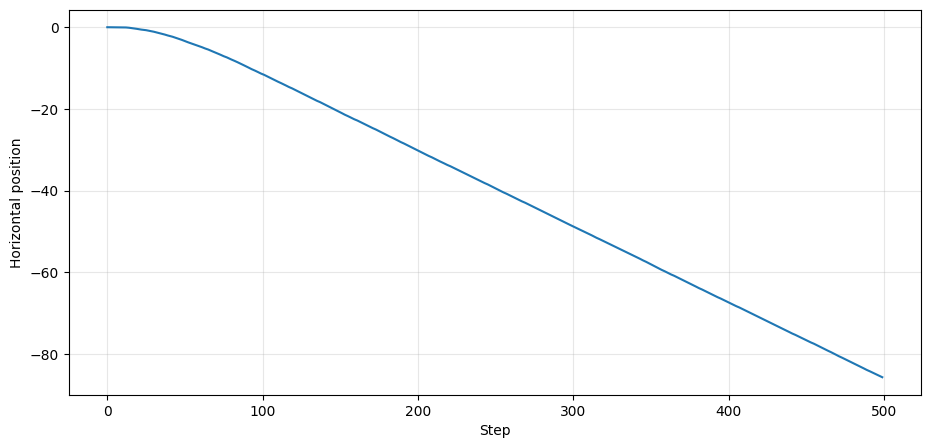

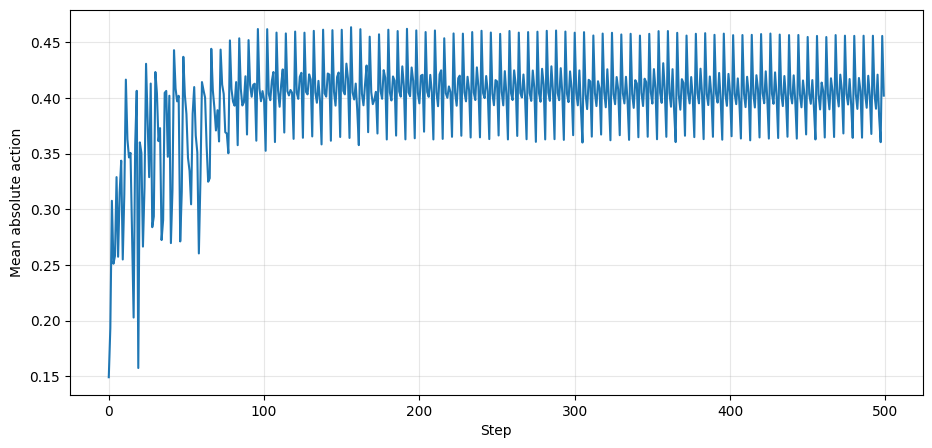

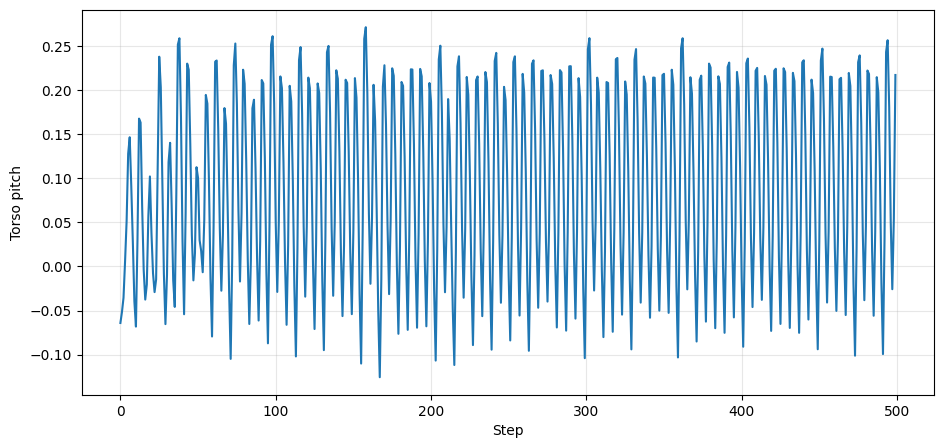

In [39]:
plt.figure(figsize=(11, 5))
plt.plot(rollout["step"], rollout["x_position"])
plt.xlabel("Step")
plt.ylabel("Horizontal position")
plt.grid(True, alpha=0.3)
plt.show()

plt.figure(figsize=(11, 5))
plt.plot(rollout["step"], rollout["mean_absolute_action"])
plt.xlabel("Step")
plt.ylabel("Mean absolute action")
plt.grid(True, alpha=0.3)
plt.show()

plt.figure(figsize=(11, 5))
plt.plot(rollout["step"], rollout["torso_pitch"])
plt.xlabel("Step")
plt.ylabel("Torso pitch")
plt.grid(True, alpha=0.3)
plt.show()

In [42]:
import time

from mujoco_py import MjViewer

viewer_environment = HalfCheetahWithPos()

viewer_state = unwrap_reset_observation(
    viewer_environment.reset(seed=EVALUATION_SEED)
)

viewer = MjViewer(viewer_environment.sim)

viewer.cam.distance = 5.0
viewer.cam.elevation = -20
viewer.cam.azimuth = 90

viewer_positions = []
viewer_actions = []
viewer_rewards = []
viewer_costs = []

for step_index in range(1000):
    step_start = time.perf_counter()

    viewer_action = deterministic_action(viewer_state)

    (
        viewer_next_state,
        viewer_reward,
        viewer_cost,
        viewer_truncated,
        viewer_terminated,
        viewer_info,
    ) = viewer_environment.step(viewer_action)

    viewer_positions.append(
        float(viewer_environment.sim.data.qpos[0])
    )
    viewer_actions.append(viewer_action.copy())
    viewer_rewards.append(float(viewer_reward))
    viewer_costs.append(float(viewer_cost))

    viewer.render()

    viewer_state = np.asarray(
        viewer_next_state,
        dtype=np.float64,
    )

    remaining_time = (
        viewer_environment.dt
        - (time.perf_counter() - step_start)
    )

    if remaining_time > 0:
        time.sleep(remaining_time)

    if viewer_truncated or viewer_terminated:
        break

viewer_environment.close()

viewer_positions = np.asarray(
    viewer_positions,
    dtype=np.float64,
)

viewer_actions = np.asarray(
    viewer_actions,
    dtype=np.float64,
)

pd.DataFrame(
    {
        "value": [
            len(viewer_positions),
            viewer_positions[-1] - viewer_positions[0],
            np.sum(viewer_rewards),
            np.sum(viewer_costs),
            np.mean(np.abs(viewer_actions)),
            np.max(np.abs(viewer_actions)),
        ]
    },
    index=[
        "steps",
        "x_displacement",
        "total_reward",
        "total_cost",
        "mean_absolute_action",
        "maximum_absolute_action",
    ],
)

/home/bannanakid/miniforge3/envs/rcrl/lib/python3.10/site-packages/gym/envs/mujoco/mujoco_env.py:190: UserWarning: WARN: This version of the mujoco environments depends on the mujoco-py bindings, which are no longer maintained and may stop working. Please upgrade to the v4 versions of the environments (which depend on the mujoco python bindings instead), unless you are trying to precisely replicate previous works).
  logger.warn(


Creating window glfw


SystemExit: 0

/home/bannanakid/.local/lib/python3.10/site-packages/IPython/core/interactiveshell.py:3587: UserWarning: To exit: use 'exit', 'quit', or Ctrl-D.
  warn("To exit: use 'exit', 'quit', or Ctrl-D.", stacklevel=1)


In [ ]:
def render_rgb(environment, width=640, height=360):

    try:

        frame = environment.render(

            mode="rgb_array",

            width=width,

            height=height,

        )

        if frame is not None:

            return np.asarray(frame, dtype=np.uint8)

    except Exception:

        pass



    frame = environment.sim.render(

        width=width,

        height=height,

        camera_name=None,

    )



    return np.flipud(

        np.asarray(frame, dtype=np.uint8)

    )





gif_environment = HalfCheetahWithPos()

gif_state = unwrap_reset_observation(

    gif_environment.reset(seed=EVALUATION_SEED)

)



frames = []

gif_positions = []

gif_actions = []



for step_index in range(GIF_STEPS):

    gif_action = deterministic_action(gif_state)



    (

        gif_next_state,

        gif_reward,

        gif_cost,

        gif_truncated,

        gif_terminated,

        gif_info,

    ) = gif_environment.step(gif_action)



    gif_positions.append(

        float(gif_environment.sim.data.qpos[0])

    )

    gif_actions.append(gif_action.copy())



    if step_index % GIF_FRAME_INTERVAL == 0:

        frame = render_rgb(gif_environment)

        frames.append(PILImage.fromarray(frame))



    gif_state = np.asarray(

        gif_next_state,

        dtype=np.float64,

    )



    if gif_truncated or gif_terminated:

        break



gif_environment.close()



gif_positions = np.asarray(gif_positions, dtype=np.float64)

gif_actions = np.asarray(gif_actions, dtype=np.float64)

gif_path = OUTPUT_DIRECTORY / "halfcheetahwithpos_run3.gif"



if len(frames) < 2:

    raise RuntimeError("Rendering returned fewer than two frames")



frames[0].save(

    gif_path,

    save_all=True,

    append_images=frames[1:],

    duration=GIF_DURATION_MS,

    loop=0,

)



display(Image(filename=str(gif_path)))



pd.DataFrame(

    {

        "value": [

            str(gif_path),

            len(frames),

            gif_positions[-1] - gif_positions[0],

            np.mean(np.abs(gif_actions)),

            np.max(np.abs(gif_actions)),

        ]

    },

    index=[

        "gif_path",

        "frame_count",

        "x_displacement",

        "mean_absolute_action",

        "maximum_absolute_action",

    ],

)

In [41]:
rollout.to_csv(
    OUTPUT_DIRECTORY / "rollout_metrics.csv",
    index=False,
)
summary.to_csv(
    OUTPUT_DIRECTORY / "rollout_summary.csv"
)
print(OUTPUT_DIRECTORY)

/home/bannanakid/RCRL_on_RCMDP/plot_data/HalfCheetahWithPos/run3/test
